# A. Import Libraries 

In [1]:
# Import necessary libraries for data analysis and visualization
import pandas as pd   # For data manipulation and analysis
import numpy as np    # For numerical operations
from scipy import stats   # For statistical functions and tests
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
import tempfile
import urllib.request
from functools import reduce
from operator import add
from pyspark.sql import functions as F


# 1. Initialize SparkSession
spark = SparkSession.builder \
    .appName("GenderPayGapEurope") \
    .getOrCreate()

# B. Pertanyaan dan Data

Latar Belakang

Kesetaraan gender merupakan pilar utama agenda pembangunan berkelanjutan Uni Eropa (SDG 5), namun kesenjangan upah antar-gender (Gender Pay Gap) masih menjadi tantangan di berbagai sektor industri. Analisis ini menggunakan data resmi Eurostat (2015–2024) untuk memetakan disparitas upah lintas sektor serta menguji pengaruh tingkat pendidikan tinggi, partisipasi kerja, dan kepemimpinan manajerial perempuan guna menghasilkan rekomendasi kebijakan berbasis data.

Kami melakukan analisis berbasis data menggunakan indikator resmi dari website Eurostat untuk mengevaluasi tren perkembangan Gender Pay Gap. Memetakan sektor industri dengan disparitas tertinggi, menguji signifikansi hubungan antara faktor pendidikan, partisipasi kerja, dan kepemimpinan perempuan terhadap penurunan kesenjangan upah.

Tujuan

Mengevaluasi tren Gender Pay Gap di Eropa (2015–2024) serta faktor-faktor yang dapat menurunkannya untuk memberikan rekomendasi kebijakan yang efektif.


Bagaimana dan mengapa: perkembangan Gender Pay Gap di Eropa  

1. Bagaimana tren gender pay gap di Eropa seiring waktu? 
2. Berdasarkan Industri, bagaimana perbandingan gender pay gap? Secara statistik, apakah perbedaan antar industri ini nyata atau hanya kebetulan?
3. Bagaimana trend tingkat edukasi wanita? Serta apa pengaruhnya terhadap gender pay gap?
4. Bagaimana tren persentase gap employment antara gender? Bagaimana pengaruhnya terhadap gender pay gap?
5. Bagaimana perkembangan tren persentase wanita masuk menjabat dalam manajemen suatu perusahaan? Bagaimana pengaruhnya terhadap gender pay gap?

Tableau Dashboard [Tableau](https://public.tableau.com/app/profile/guntur.rizkiyana.muhammad/viz/GenderDashboard_17950067272020/Dashboard1?publish=yes)

Semua dataset berdasarkan tahun 2015 -2024

Data set : Gender Pay Gap - Europe\
Bagaimana trend seiring waktu tentang pay gap
Bagaimana trend berdasarkan industri tentang pay gap

Link : (https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/earn_gr_gpgr2/1.0/*.*.*.*?c[freq]=A&c[unit]=PC&c[nace_r2]=B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,UK,ME,MK,AL,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name)

Data set : Employment Gap - Europe\
Menjelaskan gap employment rate antara pria dan wanita

Link (https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_05_30/1.0/*.*.*.*.*?c[freq]=A&c[wstatus]=EMP,EMP_PT,EMP_TEMP,UEMP_PT&c[age]=Y20-64&c[unit]=PC_PNT&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,BA,ME,MK,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name)

Data set : Women in Management Position - Europe\
Menjelaskan berapa banyak persentase wanita menjabat di bagian management suatu perusahaan
Seberapa besar persentase wanita masuk menjabat dalam manajemen suatu perusahaan?
Semakin tinggi persentase, semakin tinggi jumlah wanita yang menjabat sebagai manajemen di suatu persuahaan 

Link (https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_05_61/1.0/*.*.*.*.*?c[freq]=A&c[prof_pos]=NEXEC,NEXEC_EXEC&c[sex]=F&c[unit]=PC&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,BA,ME,MK,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name)

Data set : Female Aged 25-34 with College Level Education - Europe\
Berapa besar presentase wanita umur 25 - 34 mengenyam pendidikan kampus (kuliah)
Apakah tingkat edukasi wanita berpengaruh dengan pay gap? 
Persentasenya dibandingkan dengan keseluruhan populasi pada bracket umur 25 - 34
Link (https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_04_20/1.0/*.*.*.*.*.*?c[freq]=A&c[sex]=F&c[age]=Y25-34&c[unit]=PC&c[isced11]=ED5-8&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,BA,ME,MK,RS,TR,UK&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name)


Limitasi Data
1. Rentang waktu 2015-2024 yang dipilih sesuai dengan ketersediaan data dan 10 tahun untuk melihat tren perkembangan. 
2. Terdapat missing value karena pada data Gender Pay Gap dan Employment gap karena pada saat itu ada beberapa negara yang belum bergabung kedalam Uni Eropa.
3. Data set tertiary educational (kuliah) hanya tersedia pada umur 25-34

# C. Extract & Load Data to Pyspark

In [2]:
def read_csv(file_name):
    # If input is an HTTP/HTTPS URL, download to a local temp .csv.gz file first
    if file_name.startswith(("http://", "https://")):
        suffix = ".csv.gz" if "compress=true" in file_name else ".csv"
        tmp = tempfile.NamedTemporaryFile(delete=False, suffix=suffix)
        tmp.close()
        urllib.request.urlretrieve(file_name, tmp.name)
        local_path = tmp.name
    else:
        local_path = file_name

    return spark.read.csv(local_path, header=True, inferSchema=True, escape='"')

def to_snake_case(df):
    new_names = [
        c.strip().lower()
         .replace(' ', '_')
         .replace('-', '_')
         .replace('/', '_')
         .replace('.', '')
         .replace('(', '')
         .replace(')', '')
        for c in df.columns
    ]
    return df.toDF(*new_names)

wage_gap = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/earn_gr_gpgr2/1.0/*.*.*.*?c[freq]=A&c[unit]=PC&c[nace_r2]=B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,UK,ME,MK,AL,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))
emp_gap = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_05_30/1.0/*.*.*.*.*?c[freq]=A&c[wstatus]=EMP,EMP_PT,EMP_TEMP,UEMP_PT&c[age]=Y20-64&c[unit]=PC_PNT&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,BA,ME,MK,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))
women_mang = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_05_61/1.0/*.*.*.*.*?c[freq]=A&c[prof_pos]=NEXEC,NEXEC_EXEC&c[sex]=F&c[unit]=PC&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,BA,ME,MK,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))
women_college = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_04_20/1.0/*.*.*.*.*.*?c[freq]=A&c[sex]=F&c[age]=Y25-34&c[unit]=PC&c[isced11]=ED5-8&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,BA,ME,MK,RS,TR,UK&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))


# D. Data Exploration

## 1. Look at the data

In [3]:
wage_gap.show()

+---------+--------------------+--------------------+----+--------------+----+---------------+-------+--------------------------------------------------------------------------------------+---+-----------------------------+-----------+----+---------+-----------------+--------+------------------------------------+-----------+---------------------------+
|structure|        structure_id|      structure_name|freq|time_frequency|unit|unit_of_measure|nace_r2|statistical_classification_of_economic_activities_in_the_european_community_nace_rev_2|geo|geopolitical_entity_reporting|time_period|time|obs_value|observation_value|obs_flag|observation_status_flag_v2_structure|conf_status|confidentiality_status_flag|
+---------+--------------------+--------------------+----+--------------+----+---------------+-------+--------------------------------------------------------------------------------------+---+-----------------------------+-----------+----+---------+-----------------+--------+-------------

In [4]:
emp_gap.show()

+---------+--------------------+--------------------+----+--------------+-------+----------------------------------+------+-------------------+------+----------------+---+-----------------------------+-----------+----+---------+-----------------+--------+------------------------------------+-----------+---------------------------+
|structure|        structure_id|      structure_name|freq|time_frequency|wstatus|labour_force_and_employment_status|   age|          age_class|  unit| unit_of_measure|geo|geopolitical_entity_reporting|time_period|time|obs_value|observation_value|obs_flag|observation_status_flag_v2_structure|conf_status|confidentiality_status_flag|
+---------+--------------------+--------------------+----+--------------+-------+----------------------------------+------+-------------------+------+----------------+---+-----------------------------+-----------+----+---------+-----------------+--------+------------------------------------+-----------+---------------------------+
|

In [5]:
women_mang.show()

+---------+--------------------+--------------------+----+--------------+--------+---------------------+----+-------+----+---------------+---+-----------------------------+-----------+----+---------+-----------------+--------+------------------------------------+-----------+---------------------------+
|structure|        structure_id|      structure_name|freq|time_frequency|prof_pos|professional_position|sex7|   sex8|unit|unit_of_measure|geo|geopolitical_entity_reporting|time_period|time|obs_value|observation_value|obs_flag|observation_status_flag_v2_structure|conf_status|confidentiality_status_flag|
+---------+--------------------+--------------------+----+--------------+--------+---------------------+----+-------+----+---------------+---+-----------------------------+-----------+----+---------+-----------------+--------+------------------------------------+-----------+---------------------------+
| dataflow|ESTAT:SDG_05_61(1.0)|Positions held by...|   A|        Annual|   NEXEC| Non-e

In [6]:
women_college.show()

+---------+--------------------+--------------------+----+--------------+----+-------+------+-------------------+----+---------------+-------+-------------------------------------------------------------+---+-----------------------------+-----------+----+---------+-----------------+--------+------------------------------------+-----------+---------------------------+
|structure|        structure_id|      structure_name|freq|time_frequency|sex5|   sex6|   age|          age_class|unit|unit_of_measure|isced11|international_standard_classification_of_education_isced_2011|geo|geopolitical_entity_reporting|time_period|time|obs_value|observation_value|obs_flag|observation_status_flag_v2_structure|conf_status|confidentiality_status_flag|
+---------+--------------------+--------------------+----+--------------+----+-------+------+-------------------+----+---------------+-------+-------------------------------------------------------------+---+-----------------------------+-----------+----+-----

## 2. Rows & Column

In [7]:
print(f'Table wage_gap contains {wage_gap.count()} rows and {len(wage_gap.columns)} columns')
print(f'Table emp_gap contains {emp_gap.count()} rows and {len(emp_gap.columns)} columns')
print(f'Table Order women_mang contains {women_mang.count()} rows and {len(women_mang.columns)} columns')
print(f'Table Order women_college contains {women_college.count()} rows and {len(women_college.columns)} columns')

Table wage_gap contains 4829 rows and 19 columns
Table emp_gap contains 1360 rows and 21 columns
Table Order women_mang contains 664 rows and 21 columns
Table Order women_college contains 345 rows and 23 columns


## 3. Data Type

In [8]:
wage_gap.printSchema(),
emp_gap.printSchema(),
women_mang.printSchema(),
women_college.printSchema()


root
 |-- structure: string (nullable = true)
 |-- structure_id: string (nullable = true)
 |-- structure_name: string (nullable = true)
 |-- freq: string (nullable = true)
 |-- time_frequency: string (nullable = true)
 |-- unit: string (nullable = true)
 |-- unit_of_measure: string (nullable = true)
 |-- nace_r2: string (nullable = true)
 |-- statistical_classification_of_economic_activities_in_the_european_community_nace_rev_2: string (nullable = true)
 |-- geo: string (nullable = true)
 |-- geopolitical_entity_reporting: string (nullable = true)
 |-- time_period: integer (nullable = true)
 |-- time: string (nullable = true)
 |-- obs_value: double (nullable = true)
 |-- observation_value: string (nullable = true)
 |-- obs_flag: string (nullable = true)
 |-- observation_status_flag_v2_structure: string (nullable = true)
 |-- conf_status: string (nullable = true)
 |-- confidentiality_status_flag: string (nullable = true)

root
 |-- structure: string (nullable = true)
 |-- structure_id: 

Karena kolom yang akan dipakai adalah 'geopolitical_entity_(reporting)', 'time_period', dan 'obs_value'. Saya memastikan bahwa semua kolom di table tersebut adalah:

'geopolitical_entity_(reporting)' : string\
'time_period' : integer\
'obs_value' : double

Semua table sudah sesuai data type nya

## 4. Statistical Summary

In [9]:
wage_gap.describe().show(),
emp_gap.describe().show(),
women_mang.describe().show(),
women_college.describe().show()

+-------+---------+--------------------+--------------------+----+--------------+----+---------------+-------+--------------------------------------------------------------------------------------+----+-----------------------------+-----------------+----+------------------+-----------------+--------+------------------------------------+-----------+---------------------------+
|summary|structure|        structure_id|      structure_name|freq|time_frequency|unit|unit_of_measure|nace_r2|statistical_classification_of_economic_activities_in_the_european_community_nace_rev_2| geo|geopolitical_entity_reporting|      time_period|time|         obs_value|observation_value|obs_flag|observation_status_flag_v2_structure|conf_status|confidentiality_status_flag|
+-------+---------+--------------------+--------------------+----+--------------+----+---------------+-------+--------------------------------------------------------------------------------------+----+-----------------------------+----------

## Duplicate & Missing Value

Tabel Gender Pay Gap - Europe

In [10]:
total_rows_wage_gap = wage_gap.count()
distinct_rows_wage_gap = wage_gap.drop_duplicates().count()
duplicate_rows_wage_gap = total_rows_wage_gap - distinct_rows_wage_gap

print(f"Total Rows: {total_rows_wage_gap}")
print(f"Distinct Rows: {distinct_rows_wage_gap}")
print(f"Duplicate Rows: {duplicate_rows_wage_gap}")

Total Rows: 4829
Distinct Rows: 4829
Duplicate Rows: 0


Tidak ada data duplikat

In [11]:
print('Missing Value for table wage_gap:')

for c in wage_gap.columns:
    print(c, wage_gap[wage_gap[c].isNull()].count())

Missing Value for table wage_gap:
structure 0
structure_id 0
structure_name 0
freq 0
time_frequency 0
unit 0
unit_of_measure 0
nace_r2 0
statistical_classification_of_economic_activities_in_the_european_community_nace_rev_2 0
geo 0
geopolitical_entity_reporting 0
time_period 0
time 4829
obs_value 33
observation_value 4829
obs_flag 3493
observation_status_flag_v2_structure 3493
conf_status 4796
confidentiality_status_flag 4796


Kolom yang dipakai dan jumlah missing value\
geopolitical_entity_(reporting) 0\
time_period 0\
obs_value 33


Tabel Employement Gap - Europe

In [12]:
total_rows_emp_gap = emp_gap.count()
distinct_rows_emp_gap = emp_gap.drop_duplicates().count()
duplicate_rows_emp_gap = total_rows_emp_gap - distinct_rows_emp_gap

print(f"Total Rows: {total_rows_emp_gap}")
print(f"Distinct Rows: {distinct_rows_emp_gap}")
print(f"Duplicate Rows: {duplicate_rows_emp_gap}")

Total Rows: 1360
Distinct Rows: 1360
Duplicate Rows: 0


Tidak ada data duplikat

In [13]:
print('Missing Value for table emp_gap:')

for c in emp_gap.columns:
    print(c, emp_gap[emp_gap[c].isNull()].count())

Missing Value for table emp_gap:
structure 0
structure_id 0
structure_name 0
freq 0
time_frequency 0
wstatus 0
labour_force_and_employment_status 0
age 0
age_class 0
unit 0
unit_of_measure 0
geo 0
geopolitical_entity_reporting 0
time_period 0
time 1360
obs_value 7
observation_value 1360
obs_flag 1237
observation_status_flag_v2_structure 1237
conf_status 1360
confidentiality_status_flag 1360


Kolom yang dipakai dan jumlah missing value\
geopolitical_entity_(reporting) 0\
time_period 0\
obs_value 7


Tabel Women in Management Position - Europe

In [14]:
total_rows_women_mang = women_mang.count()
distinct_rows_women_mang = women_mang.drop_duplicates().count()
duplicate_rows_women_mang = total_rows_women_mang - distinct_rows_women_mang

print(f"Total Rows: {total_rows_women_mang}")
print(f"Distinct Rows: {distinct_rows_women_mang}")
print(f"Duplicate Rows: {duplicate_rows_women_mang}")

Total Rows: 664
Distinct Rows: 664
Duplicate Rows: 0


Tidak ada data duplikat

In [15]:
print('Missing Value for table women_mang:')

for c in women_mang.columns:
    print(c, women_mang[women_mang[c].isNull()].count())

Missing Value for table women_mang:
structure 0
structure_id 0
structure_name 0
freq 0
time_frequency 0
prof_pos 0
professional_position 0
sex7 0
sex8 0
unit 0
unit_of_measure 0
geo 0
geopolitical_entity_reporting 0
time_period 0
time 664
obs_value 0
observation_value 664
obs_flag 664
observation_status_flag_v2_structure 664
conf_status 664
confidentiality_status_flag 664


Kolom yang dipakai dan jumlah missing value\
geopolitical_entity_(reporting) 0\
time_period 0\
obs_value 0

Tabel Female Aged 25-34 with College Level Education - Europe

In [16]:
total_rows_women_college = women_college.count()
distinct_rows_women_college = women_college.drop_duplicates().count()
duplicate_rows_women_college = total_rows_women_college - distinct_rows_women_college

print(f"Total Rows: {total_rows_women_college}")
print(f"Distinct Rows: {distinct_rows_women_college}")
print(f"Duplicate Rows: {duplicate_rows_women_college}")

Total Rows: 345
Distinct Rows: 345
Duplicate Rows: 0


Tidak ada data duplikat

In [17]:
print('Missing Value for table women_college:')

for c in women_college.columns:
    print(c, women_college[women_college[c].isNull()].count())

Missing Value for table women_college:
structure 0
structure_id 0
structure_name 0
freq 0
time_frequency 0
sex5 0
sex6 0
age 0
age_class 0
unit 0
unit_of_measure 0
isced11 0
international_standard_classification_of_education_isced_2011 0
geo 0
geopolitical_entity_reporting 0
time_period 0
time 345
obs_value 0
observation_value 345
obs_flag 293
observation_status_flag_v2_structure 293
conf_status 345
confidentiality_status_flag 345


Kolom yang dipakai dan jumlah missing value\
geopolitical_entity_(reporting) 0\
time_period 0\
obs_value 0

Kesimpulan

Tidak ada data duplikat pada tiap tabel dan terdapat missing value hanya pada tabel 
1. Tabel Employement Gap 7 missing value
2. Tabel Gender Pay Gap 33 missing value

Missing value ini disebabkan karena negara tersebut belum bergabung dengan Uni Eropa sehingga datanya tidak tersedia

# 3. Transform

## Batch Cleaning

Batch cleaning akan mebersihkan data per-tabel dengan sekaligus. Data akan dibersih dengan cara:
1. Convert nama kolom menjadi snake case  
2. Drop data duplikat
3. trim white space 
4. Handle Missing value: jika string, fillna 'Unknown'. jika angka, fillna '0'

In [18]:
wage_gap_clean = (
    wage_gap.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.col("time_period").alias("year"),
        F.col("statistical_classification_of_economic_activities_in_the_european_community_nace_rev_2").alias("industry_name"),
        F.round(F.col("obs_value"),2).alias("pay_gap_percentage")
    ).fillna(0)
)

wage_gap_clean.show(truncate=False)

+------------+------------+----+--------------------------------------------------------------------+------------------+
|country_code|country_name|year|industry_name                                                       |pay_gap_percentage|
+------------+------------+----+--------------------------------------------------------------------+------------------+
|RO          |Romania     |2022|Manufacturing                                                       |21.0              |
|SI          |Slovenia    |2021|Manufacturing                                                       |11.5              |
|IT          |Italy       |2018|Water supply; sewerage, waste management and remediation activities |4.9               |
|CY          |Cyprus      |2022|Wholesale and retail trade; repair of motor vehicles and motorcycles|23.6              |
|CZ          |Czechia     |2016|Wholesale and retail trade; repair of motor vehicles and motorcycles|25.4              |
|IS          |Iceland     |2021|

In [19]:
emp_gap_clean = (
    emp_gap.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.col("time_period").alias("year"),
        F.initcap(F.trim(F.col("labour_force_and_employment_status"))).alias("employment_status_name"),
        F.round(F.col("obs_value"),2).alias("employment_gap_percentage_points")
    ).fillna(0)
)

emp_gap_clean.show(truncate=False)

+------------+------------+----+----------------------------------------+--------------------------------+
|country_code|country_name|year|employment_status_name                  |employment_gap_percentage_points|
+------------+------------+----+----------------------------------------+--------------------------------+
|BG          |Bulgaria    |2020|Employed Persons                        |8.3                             |
|ES          |Spain       |2021|Employed Persons                        |10.8                            |
|ME          |Montenegro  |2015|Employed Persons                        |10.3                            |
|CY          |Cyprus      |2017|Employed Persons Working Part-time      |-6.6                            |
|EE          |Estonia     |2018|Employed Persons Working Part-time      |-7.6                            |
|PL          |Poland      |2018|Employed Persons Working Part-time      |-5.9                            |
|BE          |Belgium     |2022|Emplo

In [20]:
women_mang_clean = (
    women_mang.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.initcap(F.trim(F.col("professional_position"))).alias("management_position_name"),
        F.col("time_period").alias("year"),
        F.round(F.col("obs_value"),2).alias("women_management_percentage")
    )
)

women_mang_clean.show()

+------------+------------+------------------------+----+---------------------------+
|country_code|country_name|management_position_name|year|women_management_percentage|
+------------+------------+------------------------+----+---------------------------+
|          CY|      Cyprus|    Non-executive Dir...|2019|                        6.9|
|          BE|     Belgium|    Non-executive Dir...|2019|                       38.6|
|          HR|     Croatia|    Non-executives An...|2021|                       20.8|
|          ME|  Montenegro|    Non-executive Dir...|2017|                       25.0|
|          RO|     Romania|    Non-executive Dir...|2015|                       11.1|
|          SK|    Slovakia|    Non-executive Dir...|2016|                       12.5|
|          TR|     Türkiye|    Non-executive Dir...|2019|                       20.3|
|          LV|      Latvia|    Non-executives An...|2024|                       27.8|
|          ME|  Montenegro|    Non-executives An...|20

In [21]:
women_college_clean = (
    women_college.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.col("time_period").alias("year"),
        F.round(F.col("obs_value"),2).alias("female_tertiary_education_percentage")
    )
)

women_college_clean.show()

+------------+--------------------+----+------------------------------------+
|country_code|        country_name|year|female_tertiary_education_percentage|
+------------+--------------------+----+------------------------------------+
|          BE|             Belgium|2015|                                49.2|
|          TR|             Türkiye|2024|                                46.5|
|          BE|             Belgium|2023|                                57.3|
|          LV|              Latvia|2021|                                55.4|
|          ME|          Montenegro|2020|                                45.0|
|          SE|              Sweden|2024|                                63.3|
|          SI|            Slovenia|2017|                                56.3|
|          SI|            Slovenia|2021|                                60.8|
|          TR|             Türkiye|2016|                                28.7|
|          BA|Bosnia And Herzeg...|2021|                        

## Cleaning Code Compilation

def read_csv(file_name):
    # If input is an HTTP/HTTPS URL, download to a local temp .csv.gz file first
    if file_name.startswith(("http://", "https://")):
        suffix = ".csv.gz" if "compress=true" in file_name else ".csv"
        tmp = tempfile.NamedTemporaryFile(delete=False, suffix=suffix)
        tmp.close()
        urllib.request.urlretrieve(file_name, tmp.name)
        local_path = tmp.name
    else:
        local_path = file_name

    return spark.read.csv(local_path, header=True, inferSchema=True, escape='"')

def to_snake_case(df):
    new_names = [
        c.strip().lower()
         .replace(' ', '_')
         .replace('-', '_')
         .replace('/', '_')
         .replace('.', '')
         .replace('(', '')
         .replace(')', '')
        for c in df.columns
    ]
    return df.toDF(*new_names)

wage_gap = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/earn_gr_gpgr2/1.0/*.*.*.*?c[freq]=A&c[unit]=PC&c[nace_r2]=B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,UK,ME,MK,AL,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))
emp_gap = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_05_30/1.0/*.*.*.*.*?c[freq]=A&c[wstatus]=EMP,EMP_PT,EMP_TEMP,UEMP_PT&c[age]=Y20-64&c[unit]=PC_PNT&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,BA,ME,MK,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))
women_mang = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_05_61/1.0/*.*.*.*.*?c[freq]=A&c[prof_pos]=NEXEC,NEXEC_EXEC&c[sex]=F&c[unit]=PC&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,BA,ME,MK,RS,TR&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))
women_college = to_snake_case(read_csv('https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/sdg_04_20/1.0/*.*.*.*.*.*?c[freq]=A&c[sex]=F&c[age]=Y25-34&c[unit]=PC&c[isced11]=ED5-8&c[geo]=BE,BG,CZ,DK,DE,EE,IE,EL,ES,FR,HR,IT,CY,LV,LT,LU,HU,MT,NL,AT,PL,PT,RO,SI,SK,FI,SE,IS,NO,CH,BA,ME,MK,RS,TR,UK&c[TIME_PERIOD]=2024,2023,2022,2021,2020,2019,2018,2017,2016,2015&compress=true&format=csvdata&formatVersion=2.0&lang=en&labels=name'))

wage_gap_clean = (
    wage_gap.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.col("time_period").alias("year"),
        F.col("statistical_classification_of_economic_activities_in_the_european_community_nace_rev_2").alias("industry_name"),
        F.round(F.col("obs_value"),2).alias("pay_gap_percentage")
    ).fillna(0)
)

emp_gap_clean = (
    emp_gap.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.col("time_period").alias("year"),
        F.initcap(F.trim(F.col("labour_force_and_employment_status"))).alias("employment_status_name"),
        F.round(F.col("obs_value"),2).alias("employment_gap_percentage_points")
    ).fillna(0)
)


women_mang_clean = (
    women_mang.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.initcap(F.trim(F.col("professional_position"))).alias("management_position_name"),
        F.col("time_period").alias("year"),
        F.round(F.col("obs_value"),2).alias("women_management_percentage")
    )
)

women_college_clean = (
    women_college.dropDuplicates().select(
        F.trim(F.col("geo")).alias("country_code"),
        F.initcap(F.trim(F.col("geopolitical_entity_reporting"))).alias("country_name"),
        F.col("time_period").alias("year"),
        F.round(F.col("obs_value"),2).alias("female_tertiary_education_percentage")
    )
)


# Data Analysis

## 1. Bagaimana tren gender pay gap di Eropa seiring waktu? 

In [22]:
yearly_trend = (wage_gap_clean.filter(F.col("pay_gap_percentage") != 0).groupBy("year")
    .agg(F.round(F.mean("pay_gap_percentage"), 2).alias("pay_gap_percentage"))
    .orderBy("year")
)

yearly_trend.show(truncate=False)

+----+------------------+
|year|pay_gap_percentage|
+----+------------------+
|2015|13.51             |
|2016|13.13             |
|2017|13.05             |
|2018|12.19             |
|2019|12.27             |
|2020|11.81             |
|2021|11.41             |
|2022|10.9              |
|2023|10.87             |
|2024|10.62             |
+----+------------------+



Berdasarkan data, trend gender pay gap semakin menurun dari tahun 2015 -2024.\
Fluktuasi menujukkan trend penurunan setiap tahun dengan kenaikan kecil pada 2019 sebesar 0.08%.\
Tahun 2017-2018 menunjukkan penurunan pay gap yang paling besar yaitu dari 13.05% menjadi 12.19% atau menurun 0.86%\
Overall, semenjak tahun 2015 hingga 2024 terdapat penurun gap pada pay gender perempuan sebesar 2.89%

Conclusion\
Pay Gap di Eropa semakin menurun setiap tahunnya sejak tahun 2015 sebesar 13.51% menjadi 10.62% pada tahun 2024

## 2. Berdasarkan Industri, bagaimana perbandingan gender pay gap? Secara statistik, apakah perbedaan antar industri ini nyata atau hanya kebetulan?

In [23]:
indust_trend = (
    wage_gap_clean.filter(F.col("pay_gap_percentage") != 0).groupBy("industry_name").agg(
        F.round(F.mean("pay_gap_percentage"), 2).alias("pay_gap_percentage"),
    )
    .orderBy("pay_gap_percentage", ascending=False)
)

indust_trend.show(truncate=False)

+--------------------------------------------------------------------+------------------+
|industry_name                                                       |pay_gap_percentage|
+--------------------------------------------------------------------+------------------+
|Financial and insurance activities                                  |26.25             |
|Wholesale and retail trade; repair of motor vehicles and motorcycles|19.08             |
|Information and communication                                       |18.83             |
|Professional, scientific and technical activities                   |17.81             |
|Manufacturing                                                       |17.3              |
|Human health and social work activities                             |17.24             |
|Arts, entertainment and recreation                                  |16.51             |
|Real estate activities                                              |12.2              |
|Education

Secara industri, bisnis dan layanan memiliki gender pay gap terbesar. 

Namun hal unik bisa kita lihat pada tabel, dimana semakin pekerjaan yang berfokus pada kerja lapangan, maka akan semakin kecil pula gap dari gender pay. Bahkan pada industri konstruksi, wanita mendapatkan gaji yang lebih besar.  

Menurut hasil riset singkat melalui informasi web. Saya menemukan bahwa pada industri dengan pekerjaan lapangan, para wanita masuk sebagai bagian manajemen yang bekerja di kantor. Sehingga mereka mendapat gaji yang lebih besar daripada pekerja dilapangan.

Selanjutnya, kita melakukan Kruskal-Wallis Test untuk menguji apakah perbedaan tingkat Gender Pay Gap antar-sektor industri bersifat signifikan secara statistik, sehingga dapat dipastikan bahwa disparitas yang terlihat antar-industri merupakan perbedaan nyata dan bukan sekadar variasi acak.

H0: Semua sektor industri memiliki tingkat Gender Pay Gap yang sama secara statistik (perbedaan angka yang terlihat hanya variasi acak / kebetulan).\
H1: Tidak semua sektor industri sama — terdapat sektor tertentu dengan tingkat Gender Pay Gap yang secara signifikan lebih tinggi atau lebih rendah.\
Alpha = 0.05

Rule = p < 0,05, maka Tolak H0 (jenis sektor industri terbukti berpengaruh signifikan terhadap besar kecilnya Gender Pay Gap).

In [24]:
indust_pd = (
    wage_gap_clean
    .filter(F.col("pay_gap_percentage") != 0)
    .select("industry_name", "pay_gap_percentage")
    .toPandas()
)

# Kelompokkan nilai pay gap per industri menjadi list of arrays
groups_by_industry = [
    group["pay_gap_percentage"].values
    for _, group in indust_pd.groupby("industry_name")
]

kw_stat, kw_pval = stats.kruskal(*groups_by_industry)

print("KRUSKAL-WALLIS TEST")
print(f"Kruskal-Wallis H-statistic : {kw_stat:.4f}")
print(f"p-value                    : {kw_pval:.4e}")
print(f"Kesimpulan: {'Perbedaan pay gap antar industri signifikan secara statistik (p < 0.05)' if kw_pval < 0.05 else 'Tidak signifikan'}\n")

KRUSKAL-WALLIS TEST
Kruskal-Wallis H-statistic : 2143.9009
p-value                    : 0.0000e+00
Kesimpulan: Perbedaan pay gap antar industri signifikan secara statistik (p < 0.05)



Kesimpulannya Perbedaan pay gap antar industri signifikan secara statistik sehingga jenis industri mempengaruhi besarnya Gender Pay Gap

## 3. Bagaimana trend tingkat edukasi wanita? Serta apa pengaruhnya terhadap gender pay gap?

In [25]:
women_college_trend = (women_college_clean.groupBy("year")
    .agg(F.round(F.mean("female_tertiary_education_percentage"), 2).alias("female_tertiary_education_percentage"))
    .orderBy("year")
)

women_college_trend.show(truncate=False)

+----+------------------------------------+
|year|female_tertiary_education_percentage|
+----+------------------------------------+
|2015|45.51                               |
|2016|46.43                               |
|2017|47.27                               |
|2018|48.12                               |
|2019|49.25                               |
|2020|50.02                               |
|2021|50.71                               |
|2022|50.96                               |
|2023|51.38                               |
|2024|52.64                               |
+----+------------------------------------+



Setiap tahun tingkat edukasi pada wanita menunjukkan tren yang postif dengan selalu naik.
Data ini menunjukkan wanita dengan umur 25 - 34 tahun dengan pendidikan kuliah.

Gabungkan kedua dataframe menjadi satu

In [26]:
edu_pay_gap = women_college_clean.join(wage_gap_clean, on=["year", "country_name", "country_code"], how="inner").filter(F.col("pay_gap_percentage") != 0).orderBy("year","country_name")

edu_pay_gap = (edu_pay_gap.groupBy("year", "country_name", "country_code")
    .agg(
        F.round(F.mean("female_tertiary_education_percentage"), 2).alias("female_tertiary_education_percentage"),
        F.round(F.mean("pay_gap_percentage"), 2).alias("pay_gap_percentage")
        ).orderBy("year")
)

edu_pay_gap.show(truncate=False)

+----+------------+------------+------------------------------------+------------------+
|year|country_name|country_code|female_tertiary_education_percentage|pay_gap_percentage|
+----+------------+------------+------------------------------------+------------------+
|2015|Austria     |AT          |41.5                                |19.26             |
|2015|Belgium     |BE          |49.2                                |6.61              |
|2015|Bulgaria    |BG          |39.6                                |11.1              |
|2015|Cyprus      |CY          |63.9                                |18.01             |
|2015|Czechia     |CZ          |38.1                                |18.02             |
|2015|Denmark     |DK          |52.0                                |11.65             |
|2015|Estonia     |EE          |49.2                                |21.0              |
|2015|Finland     |FI          |48.7                                |14.45             |
|2015|France      |FR

Ubah kedua kolom menjadi format pandas dataframe untuk analisis

In [27]:
edu_pd = edu_pay_gap.toPandas()

Cek korelasi antara `female_tertiary_education_percentage` dan `pay_gap_percentage`\
H0: ρ = 0 (tidak ada hubungan antara variasi dalam populasi)\
H1: ρ ≠ 0 (ada hubungan antara variasi dalam populasi)\
Alpha = 0,05

Alpha > p = Tolak H0 (terima H1). Hubungan antara kedua variabel signifikan secara statistik.

Cek tingkat skewness

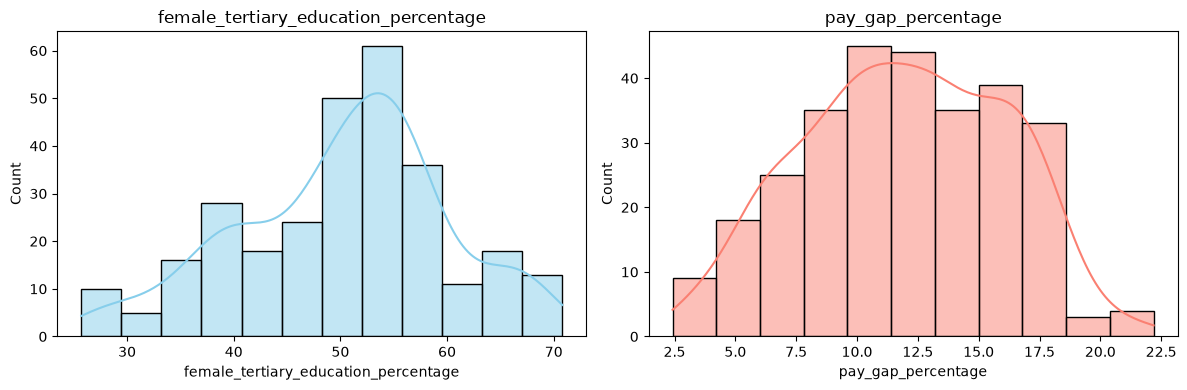

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=edu_pd, x='female_tertiary_education_percentage', kde=True, ax=axes[0], color="skyblue")
axes[0].set_title('female_tertiary_education_percentage')

sns.histplot(data=edu_pd, x="pay_gap_percentage", kde=True, ax=axes[1], color="salmon")
axes[1].set_title("pay_gap_percentage")

plt.tight_layout()
plt.show()

In [32]:
print(f"Skewness female_tertiary_education_percentage: {edu_pd['female_tertiary_education_percentage'].skew()}")
print(f"Skewness pay_gap_percentage: {edu_pd['pay_gap_percentage'].skew()}")

Skewness female_tertiary_education_percentage: -0.305475667570571
Skewness pay_gap_percentage: -0.07574420490372345


Skewness normal berada diantara -0.5 dan 0.5\
Skewness 'female_tertiary_education_percentage': -0.3\
Skewness 'pay_gap_percentage': -0.07\
Skewness kedua kolom cukup simetris dan terbilang normal.\
Sehingga, analisa korelasi yang cocok untuk keduanya adalah Pearson

In [37]:
corr_r, pval_p = stats.pearsonr(edu_pd['female_tertiary_education_percentage'], edu_pd['pay_gap_percentage'])
corr_rho, pval_s = stats.spearmanr(edu_pd['female_tertiary_education_percentage'], edu_pd['pay_gap_percentage'])
corr_tau, pval_k = stats.kendalltau(edu_pd['female_tertiary_education_percentage'], edu_pd['pay_gap_percentage'])

print(f"r-correlation: {corr_r:.2f}, p-value: {pval_p}")
print(f"rho-correlation: {corr_rho:.2f}, p-value: {pval_s}")
print(f"tau-correlation: {corr_tau:.2f}, p-value: {pval_k}")

r-correlation: -0.13, p-value: 0.026411160450291776
rho-correlation: -0.24, p-value: 2.950624448022905e-05
tau-correlation: -0.17, p-value: 1.2631278196588287e-05


Korelasi Pearson menghasilkan nilai -0.13 yang berarti `female_tertiary_education_percentage` dan `pay_gap_percentage`  memiliki hubungan negatif namun cukup lemah.\
Nilai p menghasilkan 0.026 dimana ini lebih kecil dari Alpha 0.05 yang berarti ada bukti hubungan yang signifikan secara statistik.

Kesimpulannya, semakin banyak wanita yang mengenyam pendidikan perkuliahan, maka akan semakin menurun gender pay gap. Secara statistik ada bukti bahwa ada hubungan negatif yang signifikan secara statistik antara keduanya.

## 4. Bagaimana tren persentase gap employment antara gender? Bagaimana pengaruhnya terhadap gender pay gap?

In [38]:
emp_gap_trend = (
    emp_gap_clean
    .filter(F.col("employment_gap_percentage_points") != 0).filter(F.trim(F.col("employment_status_name")) == "Employed Persons").groupBy("year").agg(
        F.round(F.mean("employment_gap_percentage_points"), 2).alias("employment_gap_percentage_points")
    )
    .orderBy("year")
)

emp_gap_trend.show(truncate=False)

+----+--------------------------------+
|year|employment_gap_percentage_points|
+----+--------------------------------+
|2015|11.26                           |
|2016|11.19                           |
|2017|11.21                           |
|2018|11.33                           |
|2019|11.12                           |
|2020|10.76                           |
|2021|11.13                           |
|2022|10.68                           |
|2023|10.2                            |
|2024|9.95                            |
+----+--------------------------------+



Berdasarkan data, selisih tenaga kerja pria dan wanita di Eropa tenaga kerja pria masih lebih besar. Namun persentase ini terus menurun selama kurun waktu 10 tahun. 

Gabungkan kedua dataframe menjadi satu

In [39]:
employ_gap = emp_gap_clean.join(wage_gap_clean, on=["year", "country_name", "country_code"], how="inner").orderBy("year","country_name")

employ_gap = (employ_gap.filter(F.col("employment_gap_percentage_points") != 0).filter(F.trim(F.col("employment_status_name")) == "Employed Persons").filter(F.col("pay_gap_percentage") != 0)
              .groupBy("year", "country_name", "country_code")
    .agg(
        F.round(F.mean("employment_gap_percentage_points"), 2).alias("employment_gap_percentage_points"),
        F.round(F.mean("pay_gap_percentage"), 2).alias("pay_gap_percentage")
        ).orderBy("year")
)

employ_gap.show(truncate=False)

+----+------------+------------+--------------------------------+------------------+
|year|country_name|country_code|employment_gap_percentage_points|pay_gap_percentage|
+----+------------+------------+--------------------------------+------------------+
|2015|Austria     |AT          |8.2                             |19.26             |
|2015|Belgium     |BE          |8.3                             |6.61              |
|2015|Bulgaria    |BG          |6.3                             |11.1              |
|2015|Cyprus      |CY          |8.3                             |18.01             |
|2015|Czechia     |CZ          |16.6                            |18.02             |
|2015|Denmark     |DK          |7.8                             |11.65             |
|2015|Estonia     |EE          |6.3                             |21.0              |
|2015|Finland     |FI          |2.1                             |14.45             |
|2015|France      |FR          |6.0                             |

Ubah kedua kolom menjadi format pandas dataframe untuk analisis

In [40]:
employ_pd = employ_gap.toPandas()

Cek korelasi antara `employment_gap_percentage_points` dan `pay_gap_percentage`\
H0: ρ = 0 (tidak ada hubungan antara variasi dalam populasi)\
H1: ρ ≠ 0 (ada hubungan antara variasi dalam populasi)\
Alpha = 0,05

Alpha > p = Tolak H0 (terima H1). Hubungan antara kedua variabel signifikan secara statistik.

Cek tingkat skewness

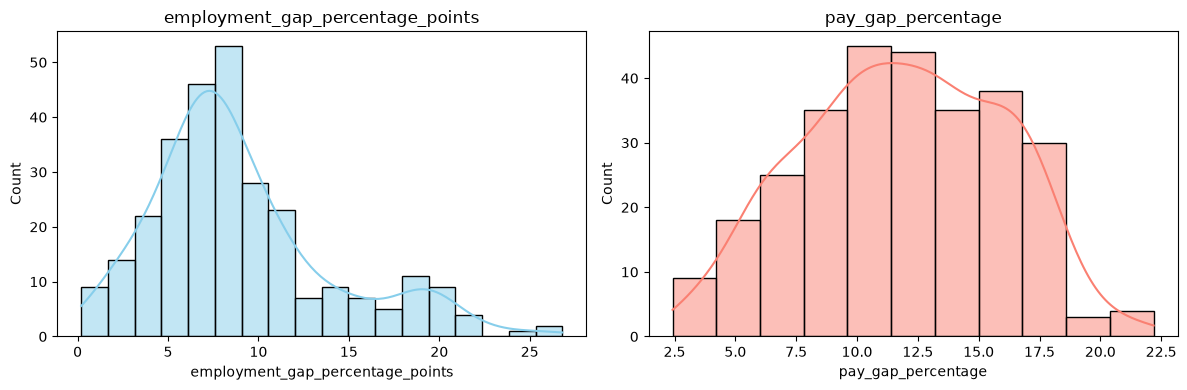

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=employ_pd, x="employment_gap_percentage_points", kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("employment_gap_percentage_points")

sns.histplot(data=employ_pd, x="pay_gap_percentage", kde=True, ax=axes[1], color="salmon")
axes[1].set_title("pay_gap_percentage")

plt.tight_layout()
plt.show()

In [42]:
print(f"Skewness employment_gap_percentage_points: {employ_pd['employment_gap_percentage_points'].skew()}")
print(f"Skewness pay_gap_percentage: {employ_pd['pay_gap_percentage'].skew()}")

Skewness employment_gap_percentage_points: 1.0488256812449326
Skewness pay_gap_percentage: -0.0597861621937853


Skewness normal berada diantara -0.5 dan 0.5\
Skewness 'employment_gap_percentage_points': 1.04\
Skewness 'pay_gap_percentage': -0.05\
Kolom `employment_gap_percentage_points` skew ke kanan dan `pay_gap_percentage` normal.\
Sehingga, analisa korelasi yang cocok untuk keduanya adalah Spearman

In [43]:
corr_r, pval_p = stats.pearsonr(employ_pd['employment_gap_percentage_points'], employ_pd['pay_gap_percentage'])
corr_rho, pval_s = stats.spearmanr(employ_pd['employment_gap_percentage_points'], employ_pd['pay_gap_percentage'])
corr_tau, pval_k = stats.kendalltau(employ_pd['employment_gap_percentage_points'], employ_pd['pay_gap_percentage'])

print(f"r-correlation: {corr_r:.2f}, p-value: {pval_p}")
print(f"rho-correlation: {corr_rho:.2f}, p-value: {pval_s}")
print(f"tau-correlation: {corr_tau:.2f}, p-value: {pval_k}")

r-correlation: 0.00, p-value: 0.9352326070580028
rho-correlation: 0.05, p-value: 0.41241384222900157
tau-correlation: 0.03, p-value: 0.42157178216389746


Korelasi Spearman menghasilkan nilai 0.05 yang berarti `employment_gap_percentage_points` dan `pay_gap_percentage`  hampir tidak memiliki hubungan karena bernilai mendekati 0.
Nilai P menghasilkan 0.41 dimana ini lebih besar dari Alpha 0.05 yang berarti tidak ada bukti hubungan yang signifikan secara statistik.

Kesimpulannya, tidak ada hubungan antara gap employment dan gender pay gap baik secara korelasi maupun statistik

## 5. Bagaimana perkembangan tren persentase wanita masuk menjabat dalam manajemen suatu perusahaan? Bagaimana pengaruhnya terhadap gender pay gap?

In [44]:
women_mang_trend = (
    women_mang_clean.groupBy("year").agg(
        F.round(F.mean("women_management_percentage"), 2).alias("women_management_percentage"),
    )
    .orderBy("year")
)

women_mang_trend.show(truncate=False)

+----+---------------------------+
|year|women_management_percentage|
+----+---------------------------+
|2015|20.25                      |
|2016|21.54                      |
|2017|22.74                      |
|2018|23.28                      |
|2019|24.92                      |
|2020|25.63                      |
|2021|27.01                      |
|2022|28.05                      |
|2023|29.1                       |
|2024|31.26                      |
+----+---------------------------+



Wanita dalam Posisi Manajerial\
Secara tren, tiap tahun persentase Wanita dalam Posisi Manajerial semakin naik setiap tahunnya

Cek korelasi antara persentase wanita yang bekerja sebagai manajemen di perusahaan dan gender pay gap

Gabungkan kedua dataframe menjadi satu, grouping berdasarkan tahun

In [46]:
women_mang_gap = women_mang_clean.join(wage_gap_clean, on=["year", "country_name", "country_code"], how="inner").filter(F.col("pay_gap_percentage") != 0).orderBy("year","country_name")

women_mang_gap = (women_mang_gap.groupBy("year", "country_name", "country_code")
    .agg(
        F.round(F.mean("women_management_percentage"), 2).alias("women_management_percentage"),
        F.round(F.mean("pay_gap_percentage"), 2).alias("pay_gap_percentage")
        ).orderBy("year")
)

women_mang_gap.show(truncate=False)

+----+------------+------------+---------------------------+------------------+
|year|country_name|country_code|women_management_percentage|pay_gap_percentage|
+----+------------+------------+---------------------------+------------------+
|2015|Austria     |AT          |18.15                      |19.26             |
|2015|Belgium     |BE          |26.7                       |6.61              |
|2015|Bulgaria    |BG          |20.85                      |11.1              |
|2015|Cyprus      |CY          |8.25                       |18.01             |
|2015|Czechia     |CZ          |10.4                       |18.02             |
|2015|Denmark     |DK          |22.8                       |11.65             |
|2015|Estonia     |EE          |9.85                       |21.0              |
|2015|Finland     |FI          |26.0                       |14.45             |
|2015|France      |FR          |36.1                       |13.08             |
|2015|Germany     |DE          |23.6    

Lanjut cek korelasi antara `women_management_percentage` dan `pay_gap_percentage`\
H0: ρ = 0 (tidak ada hubungan antara variasi dalam populasi)\
H1: ρ ≠ 0 (ada hubungan antara variasi dalam populasi)\
Alpha = 0,05

Alpha > p = Tolak H0 (terima H1). Hubungan antara kedua variabel signifikan secara statistik.

Ubah kedua kolom menjadi format pandas dataframe untuk analisis

In [47]:
wm_pd = women_mang_gap.toPandas()

Cek tingkat skewness

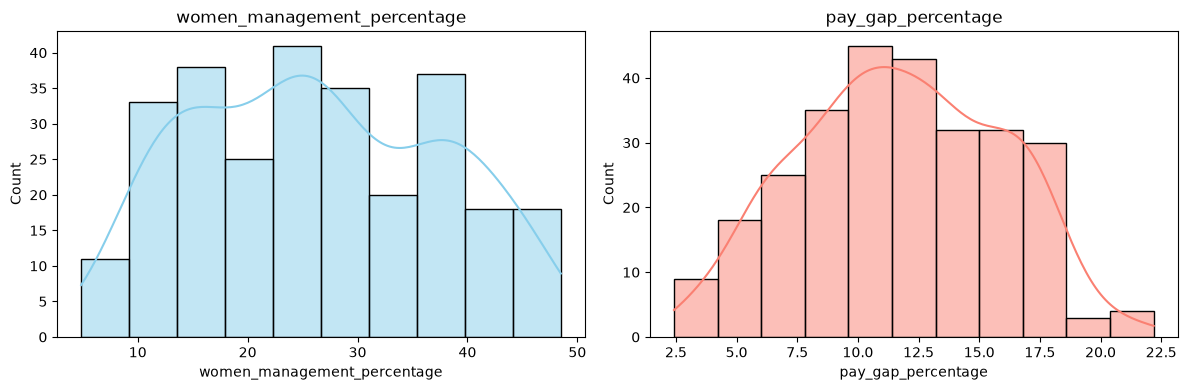

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=wm_pd, x="women_management_percentage", kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("women_management_percentage")

sns.histplot(data=wm_pd, x="pay_gap_percentage", kde=True, ax=axes[1], color="salmon")
axes[1].set_title("pay_gap_percentage")

plt.tight_layout()
plt.show()

In [49]:
print(f"Skewness women_management_percentage: {wm_pd['women_management_percentage'].skew()}")
print(f"Skewness pay_gap_percentage: {wm_pd['pay_gap_percentage'].skew()}")

Skewness women_management_percentage: 0.13157741332961678
Skewness pay_gap_percentage: -0.002157471028707464


Skewness normal berada diantara -0.5 dan 0.5\
Skewness women_management_percentage: 0.13\
Skewness pay_gap_percentage: 0.002\
Skewness kedua kolom berada diantara 0.5 dan -0.5 sehingga kedua kolom cukup simetris dan terbilang normal.\
Sehingga, analisa korelasi yang cocok untuk keduanya adalah Pearson

In [50]:
corr_r, pval_p = stats.pearsonr(wm_pd['women_management_percentage'], wm_pd['pay_gap_percentage'])
corr_rho, pval_s = stats.spearmanr(wm_pd['women_management_percentage'], wm_pd['pay_gap_percentage'])
corr_tau, pval_k = stats.kendalltau(wm_pd['women_management_percentage'], wm_pd['pay_gap_percentage'])

print(f"r-correlation: {corr_r:.2f}, p-value: {pval_p}")
print(f"rho-correlation: {corr_rho:.2f}, p-value: {pval_s}")
print(f"tau-correlation: {corr_tau:.2f}, p-value: {pval_k}")

r-correlation: -0.27, p-value: 7.05268752956625e-06
rho-correlation: -0.26, p-value: 8.211132107662581e-06
tau-correlation: -0.18, p-value: 1.0442912391143878e-05


Korelasi Pearson menghasilkan nilai -0.27 yang berarti `women_management_percentage` dan `pay_gap_percentage`  memiliki hubungan negatif sedang.\
Nilai P menghasilkan 7.05268752956625e-06 dimana ini lebih kecil dari Alpha 0.05 yang berarti ada bukti hubungan yang signifikan secara statistik.

Kesimpulannya, semakin banyak wanita yang bekerja dalam manajemen suatu perusahaan, maka akan semakin menurun gender pay gap. Statistik membuktikan bahwa ada hubungan negatif yang signifikan secara statistik antara keduanya.

# Kesimpulan

Perkembangan Gender Pay Gap di Eropa selama 2015-2024 semakin membaik. Terjadi penurunan dari 13.51% menjadi 10.62% atau menurun sebesar 2.89%. Namun perlu diingat, tiap industri memiliki besaran Gender Pay Gap yang berbeda. Gender Employment Gap tidak memiliki pengaruh yang signifikan secara statistik dalam menurunkan Gender Pay Gap. Sehingga, kita bisa berfokus pada peningkatan persentase edukasi tingkat tinggi bagi wanita dan wanita dalam posisi manajerial untuk menurunkan Gender Pay Gap secara efektif.

# Rekomendasi

Untuk menurunkan Gender Pay Gap dengan efektif, pemerintah Uni Eropa dapat merumuskan kebijakan sebagai berikut:

1. Regulasi Upah Industri: Menerapkan standar pelaporan kesenjangan upah berkala pada industri guna mengatur dan menekan ketimpangan upah, bonus dan jenjang karier.
2. Perluasan Akses Pendidikan Tinggi: Memperluas beasiswa dan akses pendidikan tinggi bagi wanita.
3. Insentif Kepemimpinan Manajerial: Memberikan insentif bagi perusahaan yang meningkatkan persentase perempuan di jajaran manajerial.

In [51]:
spark.stop()